# Practice - Training multi-layer network

In [1]:
import os
import gzip
import struct
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.optimizers import Adam


DATA_DIR = "."  # el notebook está en la misma carpeta que los .gz

In [2]:
def read_idx(filename):
    with gzip.open(filename, "rb") as f:
        zero, data_type, dims = struct.unpack(">HBB", f.read(4))
        shape = tuple(struct.unpack(">I", f.read(4))[0] for d in range(dims))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

In [3]:
def load_data(path):
    X = read_idx(os.path.join(path, "train-images-idx3-ubyte.gz"))
    y = read_idx(os.path.join(path, "train-labels-idx1-ubyte.gz"))

    X = X.astype("float32") / 255

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=123, stratify=y
    )

    return (X_train, y_train), (X_test, y_test)

Train: (48000, 28, 28) (48000,)
Test: (12000, 28, 28) (12000,)


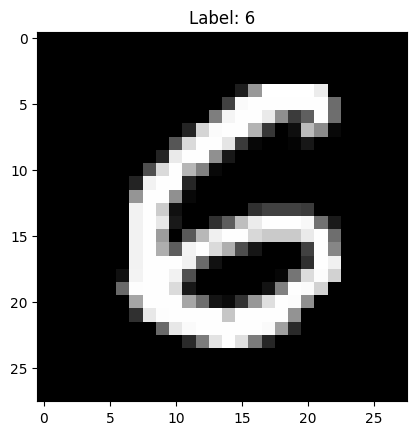

In [4]:
(X_train, y_train), (X_test, y_test) = load_data(DATA_DIR)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

plt.imshow(X_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.show()

In [5]:
def create_model(input_shape, num_classes):
    model = Sequential()
    model.add(Flatten(input_shape=input_shape))
    model.add(Dense(64, activation="relu"))
    model.add(Dense(32, activation="relu"))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["acc"],
    )
    return model

In [6]:
create_model((28, 28), 10).summary()

/Users/carloscarranza/miniconda3/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,018 (207.10 KB)

 Trainable params: 53,018 (207.10 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
def train_model(model, train_data, test_data, batch_size=32, epochs=5):
    model.fit(
        train_data[0], train_data[1],
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        shuffle=True,
        verbose=2,
    )
    return model

In [9]:
model = create_model((28, 28), 10)
model_trained = train_model(
    model,
    (X_train, y_train),
    (X_test, y_test),
    batch_size=32,
    epochs=10,
)

/Users/carloscarranza/miniconda3/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 - 2s - 1ms/step - acc: 0.8981 - loss: 0.3437 - val_acc: 0.9487 - val_loss: 0.1766
Epoch 2/10
1500/1500 - 1s - 780us/step - acc: 0.9563 - loss: 0.1454 - val_acc: 0.9592 - val_loss: 0.1404
Epoch 3/10
1500/1500 - 1s - 760us/step - acc: 0.9683 - loss: 0.1064 - val_acc: 0.9641 - val_loss: 0.1228
Epoch 4/10
1500/1500 - 1s - 831us/step - acc: 0.9742 - loss: 0.0839 - val_acc: 0.9667 - val_loss: 0.1160
Epoch 5/10
1500/1500 - 1s - 753us/step - acc: 0.9775 - loss: 0.0688 - val_acc: 0.9693 - val_loss: 0.1048
Epoch 6/10
1500/1500 - 1s - 922us/step - acc: 0.9817 - loss: 0.0560 - val_acc: 0.9699 - val_loss: 0.1014
Epoch 7/10
1500/1500 - 1s - 833us/step - acc: 0.9840 - loss: 0.0483 - val_acc: 0.9697 - val_loss: 0.1148
Epoch 8/10
1500/1500 - 1s - 915us/step - acc: 0.9874 - loss: 0.0397 - val_acc: 0.9712 - val_loss: 0.1053
Epoch 9/10
1500/1500 - 1s - 882us/step - acc: 0.9873 - loss: 0.0379 - val_acc: 0.9721 - val_loss: 0.1065
Epoch 10/10
1500/1500 - 1s - 854us/step - acc: 0.9903 - l